# Uplift Modeling: Can a Model Target Better Than a Simple Rule?

`analysis.ipynb` found a simple targeting rule: send the women's email to customers who buy only women's products,
and the men's email to everyone else. This notebook asks whether a machine-learning model, using all customer
characteristics together, can find better targeting.

**Summary**
- The model learns the same pattern found in `analysis.ipynb` (the women's email does not work on men's-only
  buyers), and ranks customers clearly better than random for the **women's** email.
- For the **men's** email there is little to rank: apart from the top 10% (mostly customers who buy both
  categories), it works about equally on everyone.
- As a targeting strategy, the model does **not** beat the simple buyer-type rule, and neither is significantly
  better than sending the men's email to everyone.
- **Conclusion:** for this campaign the simple rule is the better choice: same results, and easy to explain and run.

### Why "who will visit?" is the wrong question
A normal model predicts who will visit. But many of those people would have visited anyway, so emailing them
changes nothing. What matters is who visits **because of** the email. Every customer falls into one of four types:

| | Visits **with** email | Does not visit with email |
|---|---|---|
| **Visits without email** | Sure thing: email is wasted | Sleeping dog: email backfires |
| **Does not visit without email** | **Persuadable: target these** | Lost cause |

The difficulty: each customer was either emailed or not, never both, so their type can never be observed
directly. An **uplift model** estimates it.

### Method: T-learner ("two models")
1. Train one model on emailed customers only: it learns $P(\text{visit} \mid \text{email})$.
2. Train another on non-emailed customers only: it learns $P(\text{visit} \mid \text{no email})$.
3. For any customer, **predicted uplift = model 1's prediction − model 2's prediction.**

With two different emails, there are three models (men's, women's, none) and two uplift scores per customer.
The outcome is **visit**, since conversions are too rare (about 580 in total) to model reliably.

## 1. Setup
This notebook uses the cleaned data saved by `analysis.ipynb`, so run that notebook first.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split

pd.set_option("display.float_format", "{:.4f}".format)

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
CLEAN_PATH = REPO_ROOT / "data" / "data_clean.csv"
OUTPUT_DIR = REPO_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

assert CLEAN_PATH.exists(), "Run analysis.ipynb first to create data_clean.csv"
df = pd.read_csv(CLEAN_PATH)

EMAILS = ["Mens E-Mail", "Womens E-Mail"]
CONTROL = "No E-Mail"
OUTCOME = "visit"

## 2. Features
Only **pre-treatment** variables are used, i.e. information known before the email was sent. Using outcomes such
as `conversion` would leak the answer into the model. Text columns are turned into 0/1 columns (one-hot encoding).
`history_segment` and its derived columns are left out because they are just `history` in ranges.

In [2]:
feature_cols = ["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]
X = pd.get_dummies(df[feature_cols], drop_first=True).astype(float)
X.head()

,recency,history,mens,womens,newbie,zip_code_Suburban,zip_code_Urban,channel_Phone,channel_Web
0,10.0000,142.4400,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000
1,6.0000,329.0800,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000
2,7.0000,180.6500,0.0000,1.0000,1.0000,1.0000,0.0000,0.0000,1.0000
3,9.0000,675.8300,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000
4,2.0000,45.3400,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000


## 3. Train / test split
70% of customers are used to train the models and 30% are held back to evaluate them. The split is stratified on
email group × visit, so both parts have the same mix of groups and visitors.

In [3]:
strata = df["segment"] + "_" + df[OUTCOME].astype(str)
train_idx, test_idx = train_test_split(df.index, test_size=0.3, random_state=42, stratify=strata)

train, test = df.loc[train_idx], df.loc[test_idx]
pd.crosstab(test["segment"], test[OUTCOME], margins=True)

visit,0,1,All
segment,,,
Mens E-Mail,5224,1168,6392
No E-Mail,5713,679,6392
Womens E-Mail,5445,971,6416
All,16382,2818,19200


## 4. Train one model per group
Gradient boosting (`HistGradientBoostingClassifier`) is used because it captures interactions automatically,
for example "the women's email works only if the customer buys women's products". The trees are kept shallow
(`max_depth=3`) to limit overfitting, since the signal is small.

In [4]:
models = {}
for group in EMAILS + [CONTROL]:
    rows = train.index[train["segment"] == group]
    model = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=0)
    model.fit(X.loc[rows], df.loc[rows, OUTCOME])
    models[group] = model

# Predicted visit probability for every test customer under each scenario
pred = pd.DataFrame(
    {group: m.predict_proba(X.loc[test_idx])[:, 1] for group, m in models.items()},
    index=test_idx,
)
pred["uplift_mens"] = pred["Mens E-Mail"] - pred[CONTROL]
pred["uplift_womens"] = pred["Womens E-Mail"] - pred[CONTROL]
pred.describe().loc[["mean", "min", "50%", "max"]]

,Mens E-Mail,Womens E-Mail,No E-Mail,uplift_mens,uplift_womens
mean,0.1828,0.1516,0.1066,0.0762,0.0450
min,0.0726,0.0345,0.0169,-0.0914,-0.0995
50%,0.1758,0.1420,0.1083,0.0730,0.0428
max,0.4092,0.5104,0.2903,0.2390,0.3664


Almost every customer has a positive predicted uplift for the men's email, which agrees with `analysis.ipynb`:
it works for everyone. The women's email has a wider range, including customers near zero.

A quick sanity check: the average predicted uplift by buyer type should reproduce the pattern found earlier.

In [5]:
check = test[["mens", "womens"]].join(pred[["uplift_mens", "uplift_womens"]])
check["buyer_type"] = np.select(
    [(check["mens"] == 1) & (check["womens"] == 1), check["mens"] == 1],
    ["both", "mens only"], default="womens only",
)
(check.groupby("buyer_type")[["uplift_mens", "uplift_womens"]].mean() * 100).rename(
    columns=lambda c: c + "_pts"
)

,uplift_mens_pts,uplift_womens_pts
buyer_type,,
both,12.0677,6.6272
mens only,6.8476,1.1872
womens only,7.4091,7.3552


The model has learned the buyer-type pattern on its own: low women's-email uplift for men's-only buyers.

## 5. Does the uplift score rank customers correctly?
An individual's true uplift is never observed, so the model is checked on **groups** of test customers:

1. Sort test customers by predicted uplift and cut them into 10 equal groups (deciles).
2. In each decile, compare the actual visit rate of emailed vs non-emailed customers.

If the model works, the actual lift should be highest in the top decile and fall towards the bottom.

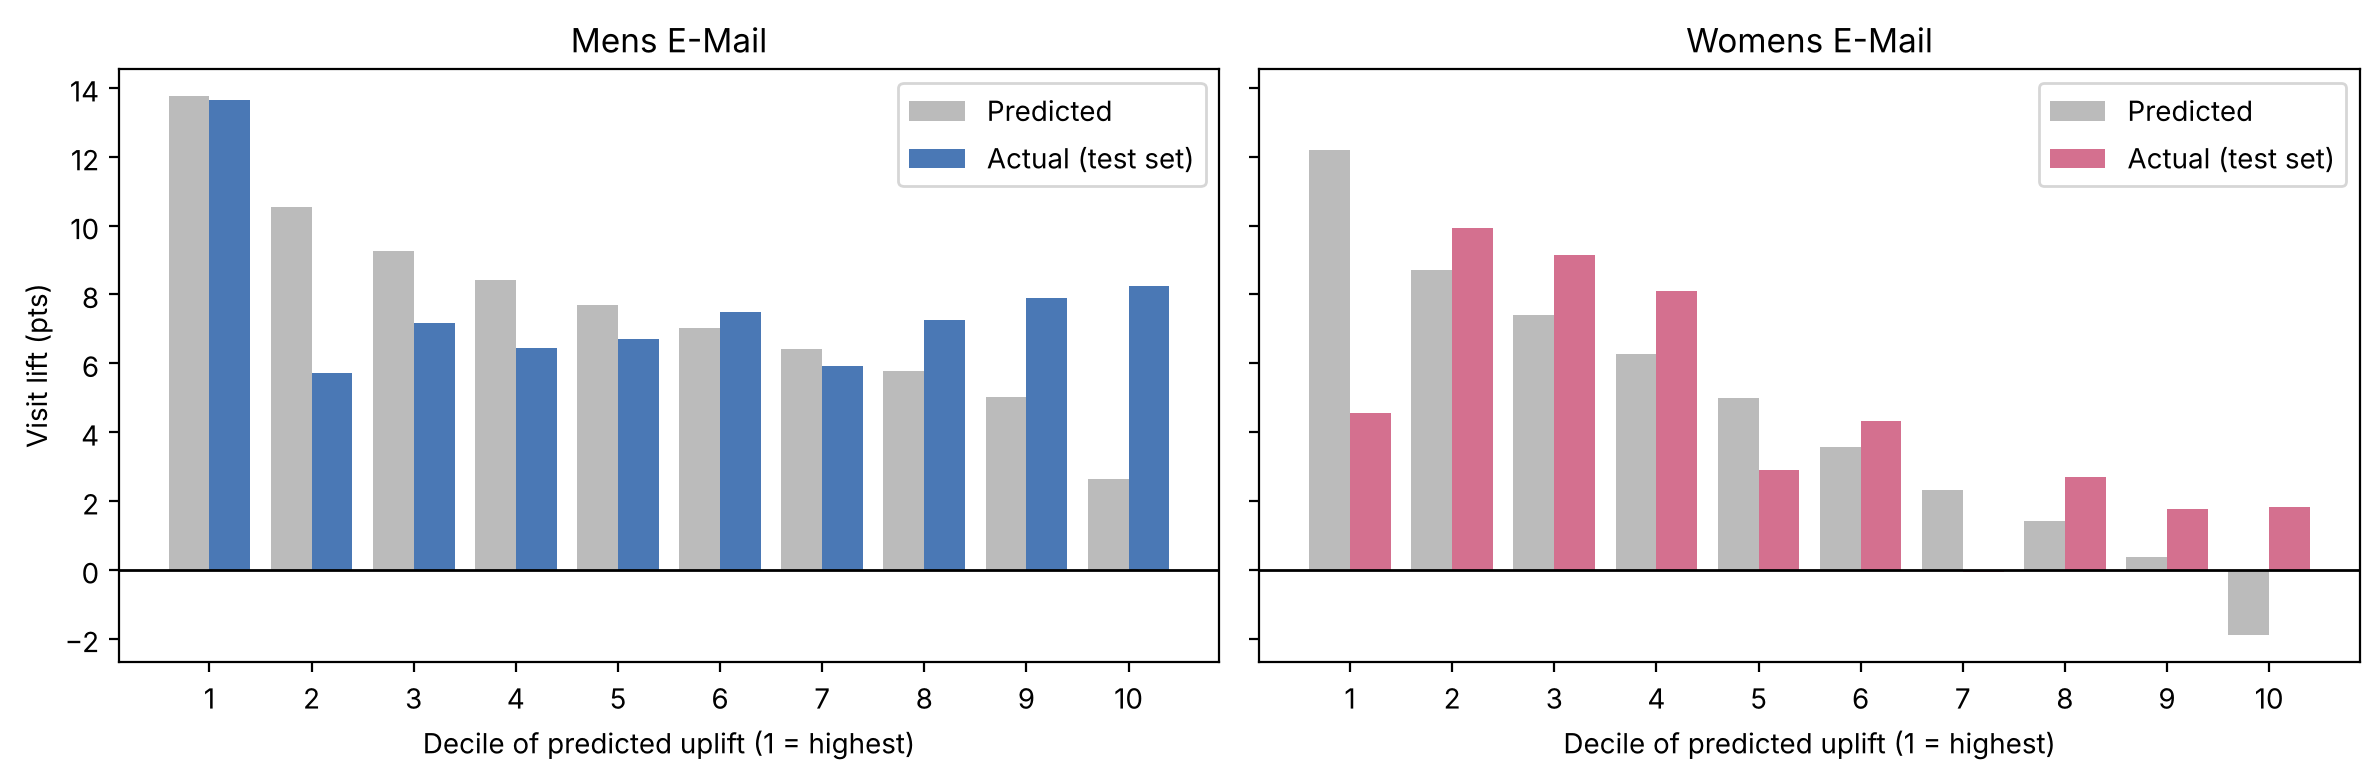

In [6]:
def observed_lift_by_decile(email, uplift_col, n_bins=10):
    sub = test[test["segment"].isin([email, CONTROL])].copy()
    sub["uplift"] = pred.loc[sub.index, uplift_col]
    # decile 1 = highest predicted uplift
    sub["decile"] = pd.qcut(sub["uplift"].rank(method="first", ascending=False), n_bins, labels=range(1, n_bins + 1))
    rates = sub.groupby(["decile", "segment"], observed=True)[OUTCOME].mean().unstack()
    return pd.DataFrame({
        "predicted_pts": sub.groupby("decile", observed=True)["uplift"].mean() * 100,
        "actual_pts": (rates[email] - rates[CONTROL]) * 100,
    })


deciles = {
    "Mens E-Mail": observed_lift_by_decile("Mens E-Mail", "uplift_mens"),
    "Womens E-Mail": observed_lift_by_decile("Womens E-Mail", "uplift_womens"),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (email, d) in zip(axes, deciles.items()):
    x = np.arange(1, 11)
    ax.bar(x - 0.2, d["predicted_pts"], width=0.4, label="Predicted", color="#bbbbbb")
    ax.bar(x + 0.2, d["actual_pts"], width=0.4, label="Actual (test set)",
           color="#4a78b5" if email == "Mens E-Mail" else "#d4708f")
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xticks(x)
    ax.set_xlabel("Decile of predicted uplift (1 = highest)")
    ax.set_title(email)
    ax.legend()
axes[0].set_ylabel("Visit lift (pts)")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "uplift_deciles.png", dpi=150)
plt.show()

**Reading the chart**
- **Men's email:** the top decile really does have a much higher lift (about +14 pts; mostly customers who buy
  both men's and women's products). Below that, actual lift stays roughly flat between +5.7 and +8.2 pts no matter what the
  model predicts. In other words, apart from the top 10%, there is little difference between customers for the model to find.
- **Women's email:** a downward trend, with some noise. Deciles 2–4 respond strongly (+8 to +10 pts), deciles 7–10
  hardly at all (about 0 to +3 pts), and the middle is mixed. The model separates customers who respond to the women's email
  from those who don't.
- The model's single highest decile for the women's email is over-optimistic (predicted +12, actual +5). Extreme
  predictions are where a model is most likely to be fitting noise.

## 6. Qini curve
The Qini curve answers: *if only the top X% of customers (ranked by the model) were emailed, how many extra
visits would that produce?*

Going down the ranked list, at each point:

$$\text{extra visits} = \text{visits}_{\text{emailed}} - \text{visits}_{\text{not emailed}} \times \frac{n_{\text{emailed}}}{n_{\text{not emailed}}}$$

The second term scales the control group to the same size as the emailed group, so the two are comparable.
The straight diagonal line is **random targeting**: emailing 30% of customers at random gives 30% of the extra
visits. A good model curves above that line, because it puts persuadable customers first.

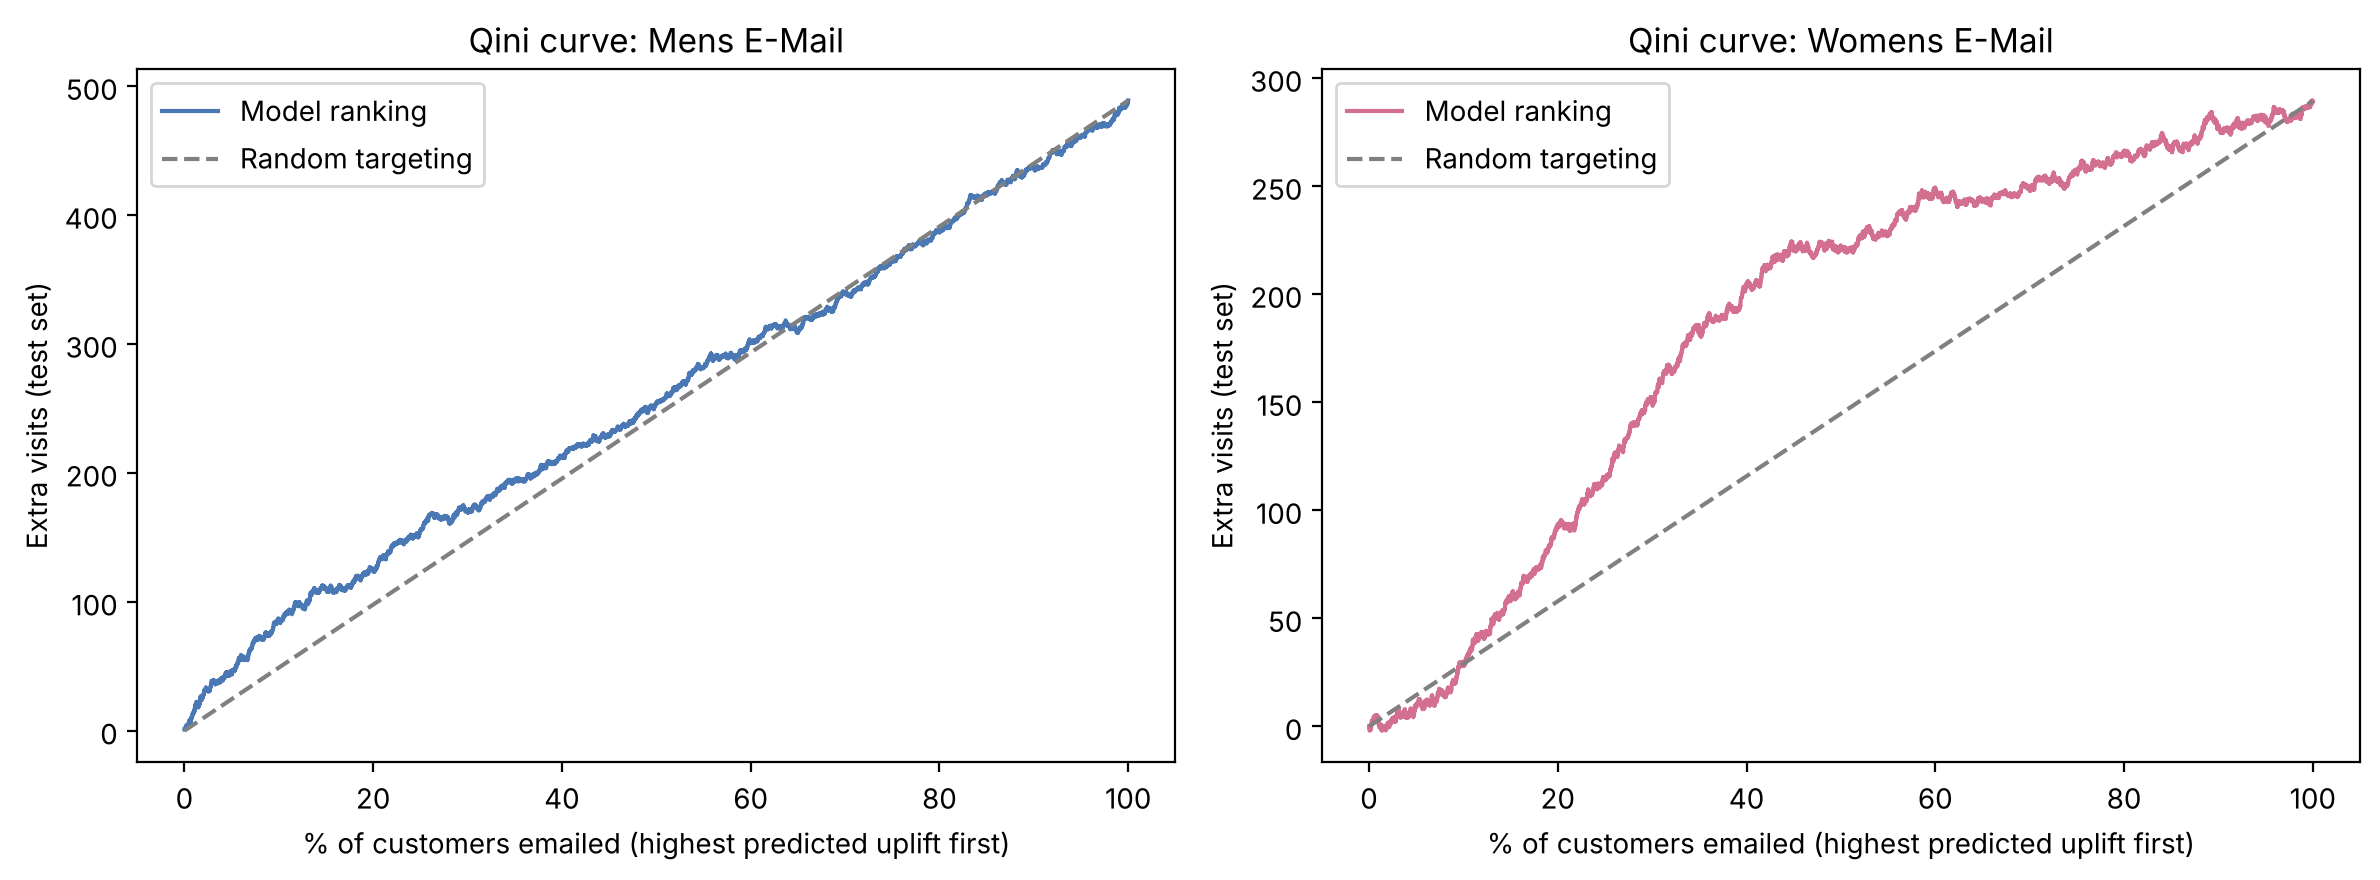

,extra_visits_all,extra_visits_top30%,share_captured_by_top30%
Mens E-Mail,489.0000,170.2956,0.3483
Womens E-Mail,289.4506,151.0000,0.5217


In [7]:
def qini_curve(email, uplift_col):
    sub = test[test["segment"].isin([email, CONTROL])].copy()
    sub["uplift"] = pred.loc[sub.index, uplift_col]
    sub = sub.sort_values("uplift", ascending=False)

    treated = (sub["segment"] == email).values
    y = sub[OUTCOME].values
    n_t, n_c = np.cumsum(treated), np.cumsum(~treated)
    y_t, y_c = np.cumsum(y * treated), np.cumsum(y * ~treated)

    extra = y_t - y_c * np.divide(n_t, n_c, out=np.zeros(len(sub)), where=n_c > 0)
    share_targeted = np.arange(1, len(sub) + 1) / len(sub)
    return share_targeted, extra


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
qini_summary = {}
for ax, email, col, color in zip(axes, EMAILS, ["uplift_mens", "uplift_womens"], ["#4a78b5", "#d4708f"]):
    x, extra = qini_curve(email, col)
    ax.plot(x * 100, extra, color=color, label="Model ranking")
    ax.plot([0, 100], [0, extra[-1]], color="gray", linestyle="--", label="Random targeting")
    ax.set_xlabel("% of customers emailed (highest predicted uplift first)")
    ax.set_ylabel("Extra visits (test set)")
    ax.set_title(f"Qini curve: {email}")
    ax.legend()
    at_30 = extra[int(0.3 * len(extra)) - 1]
    qini_summary[email] = {"extra_visits_all": extra[-1], "extra_visits_top30%": at_30,
                           "share_captured_by_top30%": at_30 / extra[-1]}
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "qini_curves.png", dpi=150)
plt.show()

pd.DataFrame(qini_summary).T

**Reading the curves**
- **Men's email:** the model curve stays close to the random line. Emailing the top 30% captures about 35% of
  the total extra visits, barely more than the 30% random targeting would give. Since the email works on
  almost everyone, there is no group worth skipping.
- **Women's email:** the curve rises well above the random line. The top 30% capture about half of all the extra
  visits, and after about 40–50% the curve flattens: the remaining customers add few extra visits.

## 7. Model-based targeting vs the simple rule
Finally, the model is turned into a decision: for each test customer, send whichever email has the higher
predicted uplift (or nothing, if both are negative). That strategy is compared with the alternatives.

**How a strategy can be evaluated without running a new experiment.** For each test customer, the strategy
recommends one email. Customers whose *actual* random assignment happens to match the recommendation show what
the strategy would achieve. Since each group was assigned with probability of about 1/3, those matching customers
are weighted up by 1 / (probability of their group). This is called **inverse propensity weighting (IPW)**:

$$\text{estimated visit rate} = \frac{1}{N}\sum_{i} \frac{y_i \cdot \mathbb{1}[\text{actual}_i = \text{recommended}_i]}{P(\text{actual}_i)}$$

To see whether differences between strategies are real, the difference to "men's email to all" is bootstrapped.

In [8]:
propensity = test["segment"].map(df["segment"].value_counts(normalize=True)).values
y_test = test[OUTCOME].values
actual = test["segment"].values

model_choice = np.where(
    (pred["uplift_mens"] >= pred["uplift_womens"]) & (pred["uplift_mens"] > 0), "Mens E-Mail",
    np.where(pred["uplift_womens"] > 0, "Womens E-Mail", CONTROL),
)
womens_only = ((test["womens"] == 1) & (test["mens"] == 0)).values

strategies = {
    "No email": np.full(len(test), CONTROL),
    "Women's email to all": np.full(len(test), "Womens E-Mail"),
    "Men's email to all": np.full(len(test), "Mens E-Mail"),
    "Simple rule (analysis.ipynb)": np.where(womens_only, "Womens E-Mail", "Mens E-Mail"),
    "Uplift model": model_choice,
}

def ipw_terms(choice):
    # Per-customer contribution to the IPW estimate
    return y_test * (actual == choice) / propensity

rng = np.random.default_rng(42)
boot_idx = rng.integers(0, len(test), size=(2000, len(test)))
baseline = ipw_terms(strategies["Men's email to all"])

rows = []
for name, choice in strategies.items():
    terms = ipw_terms(choice)
    diff_boot = (terms - baseline)[boot_idx].mean(axis=1)
    rows.append({
        "strategy": name,
        "est_visit_rate": terms.mean(),
        "vs_mens_to_all_pts": (terms - baseline).mean() * 100,
        "ci_low_pts": np.percentile(diff_boot, 2.5) * 100,
        "ci_high_pts": np.percentile(diff_boot, 97.5) * 100,
    })

pd.DataFrame(rows).set_index("strategy")

,est_visit_rate,vs_mens_to_all_pts,ci_low_pts,ci_high_pts
strategy,,,,
No email,0.1062,-7.6496,-8.9168,-6.3820
Women's email to all,0.1513,-3.1388,-4.4686,-1.8588
Men's email to all,0.1827,0.0000,0.0000,0.0000
Simple rule (analysis.ipynb),0.1874,0.4717,-0.4807,1.3602
Uplift model,0.1849,0.2180,-0.4695,0.9044


In [9]:
pd.Series(model_choice).value_counts().rename("customers assigned by model")

Mens E-Mail      14458
Womens E-Mail     4636
No E-Mail          106
Name: customers assigned by model, dtype: int64

**Reading the results**
- "No email" and "Women's email to all" are clearly worse than "Men's email to all" (their intervals are entirely
  below zero).
- The **simple rule** (+0.5 pts) and the **uplift model** (+0.2 pts) both come out slightly ahead of "Men's email to
  all", but both confidence intervals include zero. **Neither is a proven improvement.**
- The model sends the men's email to about 75% of customers, the women's email to about 24%, and nothing to almost
  nobody (about 0.5%).

## 8. Conclusion
- The uplift model found real structure: it rediscovered the buyer-type effect and ranks customers well for the
  women's email.
- But as a targeting tool it does not beat the simple rule from `analysis.ipynb`, and neither beats "men's email to
  all" by a significant margin.
- **Recommendation:** use the simple rule (or just the men's email for everyone). A model adds complexity to build,
  maintain and explain, and it should earn that with a measurable gain. Here it doesn't.

**When uplift modeling would be worth it:** when sending has a real cost per customer (a discount coupon, a
printed catalog, a sales call), or when some customers react negatively (unsubscribes). Then *not* contacting
low-uplift customers saves money, and ranking quality matters much more than it does for a near-free email.